# Bab 14 — Long Short-Term Memory
**Acuan:** Trask, *Grokking Deep Learning*, Bab 14 (hlm. 265–280).

Tujuan: memahami cell state, gates, masalah gradien, truncated BPTT, dan character language modeling. Korpus periodik buatan sendiri menggantikan Shakespeare. Agar semua komputasi tetap mudah ditelusuri, optimasi LSTM mini memakai finite difference; ini adaptasi pedagogis yang jauh lebih lambat daripada autograd/BPTT buku.

## Memory dan gates
LSTM memiliki forget gate f, input gate i, kandidat g, dan output gate o. Cell state diperbarui c_t=f_t*c_(t−1)+i_t*g_t, lalu h_t=o_t*tanh(c_t). Sigmoid membatasi gates ke (0,1), sedangkan tanh membatasi kandidat. Jalur aditif cell membantu menjaga informasi; ia tidak menjamin semua masalah vanishing gradient hilang. Turunan lokal terhadap cell sebelumnya sepanjang jalur langsung adalah f_t, sehingga gate mendekati satu mempertahankan sinyal lebih lama.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng=np.random.default_rng(14)
sigmoid=lambda x:1/(1+np.exp(-np.clip(x,-30,30)))
alphabet='ab'; hidden=2; width=2+hidden
W=rng.normal(0,.2,(width,4*hidden)); bias=np.zeros(4*hidden)
V=rng.normal(0,.2,(hidden,2)); output_bias=np.zeros(2)
parameters=[W,bias,V,output_bias]
def step(token,h,c):
    joined=np.r_[np.eye(2)[token],h]
    z=joined@W+bias
    f=sigmoid(z[:2]); i=sigmoid(z[2:4]); g=np.tanh(z[4:6]); o=sigmoid(z[6:])
    c=f*c+i*g; h=o*np.tanh(c)
    logits=h@V+output_bias; p=np.exp(logits-logits.max()); p/=p.sum()
    return h,c,p
tokens=np.array([0,1,0,1,0,1,0])
def chunk_loss():
    h=np.zeros(hidden); c=np.zeros(hidden); loss=0.
    for token,target in zip(tokens[:-1],tokens[1:]):
        h,c,p=step(token,h,c); loss-=np.log(p[target]+1e-12)
    return loss/(len(tokens)-1)
print('Jumlah parameter:',sum(p.size for p in parameters),'loss awal:',chunk_loss())

Jumlah parameter: 46 loss awal: 0.7006905027056128


## Training mini dan batas finite difference
Turunan dL/dθ diperkirakan dengan [L(θ+ε)−L(θ−ε)]/(2ε). Setiap parameter memerlukan dua forward pass sehingga metode ini hanya layak untuk contoh sangat kecil; LSTM praktis memakai reverse-mode autograd dan BPTT. Contoh mengoptimalkan satu chunk enam transisi dan mereset state pada awal chunk. Truncated BPTT umumnya membawa nilai state ke chunk berikutnya sambil memutus graph gradien pada batas chunk; mereset state seperti di sini adalah kebijakan yang berbeda dan menghilangkan konteks lintas chunk.

Loss awal/akhir: 0.7006905027056128 0.040722678087252835


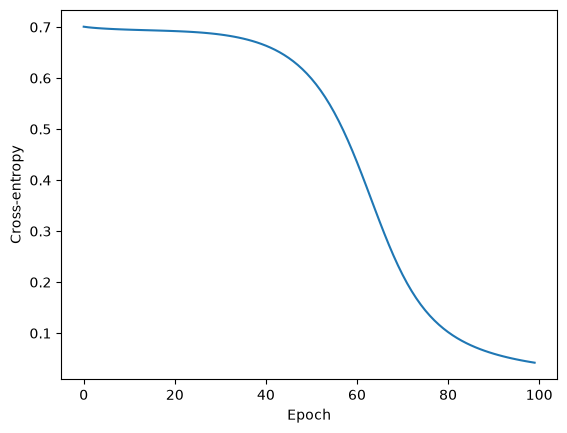

Greedy sample: ababababababababababa


In [2]:
losses=[]; epsilon=1e-4
for epoch in range(100):
    losses.append(chunk_loss()); grads=[]
    for parameter in parameters:
        grad=np.zeros_like(parameter)
        for idx in np.ndindex(parameter.shape):
            value=parameter[idx]
            parameter[idx]=value+epsilon; plus=chunk_loss()
            parameter[idx]=value-epsilon; minus=chunk_loss()
            parameter[idx]=value
            grad[idx]=(plus-minus)/(2*epsilon)
        grads.append(grad)
    for parameter,grad in zip(parameters,grads): parameter-=.8*grad
print('Loss awal/akhir:',losses[0],chunk_loss())
plt.plot(losses); plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.show()
assert chunk_loss()<losses[0]
h=np.zeros(hidden); cell=np.zeros(hidden); token=0; generated='a'
for _ in range(20):
    h,cell,p=step(token,h,cell); token=int(p.argmax()); generated+=alphabet[token]
print('Greedy sample:',generated)

## Sampling, truncated BPTT, dan ringkasan
Greedy sampling memilih kelas terbesar; stochastic sampling dari softmax dengan temperature positif memberi variasi. Temperature rendah menajamkan distribusi, tinggi meratakannya. Pelatihan teks nyata membutuhkan korpus besar, urutan validasi terpisah, batch/chunk, pemotongan norm gradien, dan optimasi efisien. LSTM memperkenalkan kontrol memori melalui gates; penurunan loss pada pola dua karakter hanya membuktikan mekanisme mini ini berjalan, bukan kemampuan menulis bahasa alami.